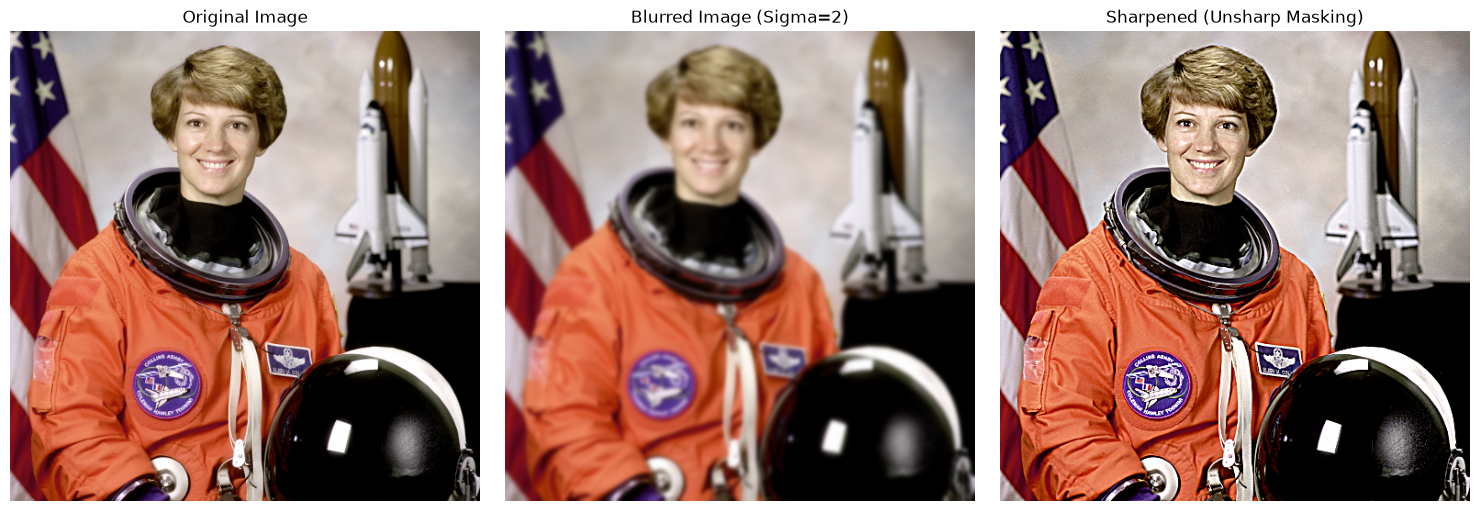

In [17]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

# Load benchmark image directly
image_rgb = data.astronaut()

# Save a copy to images/Parrot.png if needed
try:
    cv2.imwrite('images/Parrot.png', cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR))
except Exception:
    pass

image = image_rgb

sigma = 2
amount = 1.5

# Convert image to float32 for processing
image_float = image.astype(np.float32) / 255.0

# Apply Gaussian blur
blurred = cv2.GaussianBlur(image_float, (0, 0), sigmaX=sigma, sigmaY=sigma)

# Perform Unsharp Masking
sharpened = np.clip(image_float + amount * (image_float - blurred), 0, 1)

# Plot original, blurred, and sharpened images
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(image)
ax[0].set_title("Original Image")
ax[0].axis("off")

ax[1].imshow(blurred)
ax[1].set_title("Blurred Image (Sigma=2)")
ax[1].axis("off")

ax[2].imshow(sharpened)
ax[2].set_title("Sharpened (Unsharp Masking)")
ax[2].axis("off")

plt.tight_layout()
plt.show()

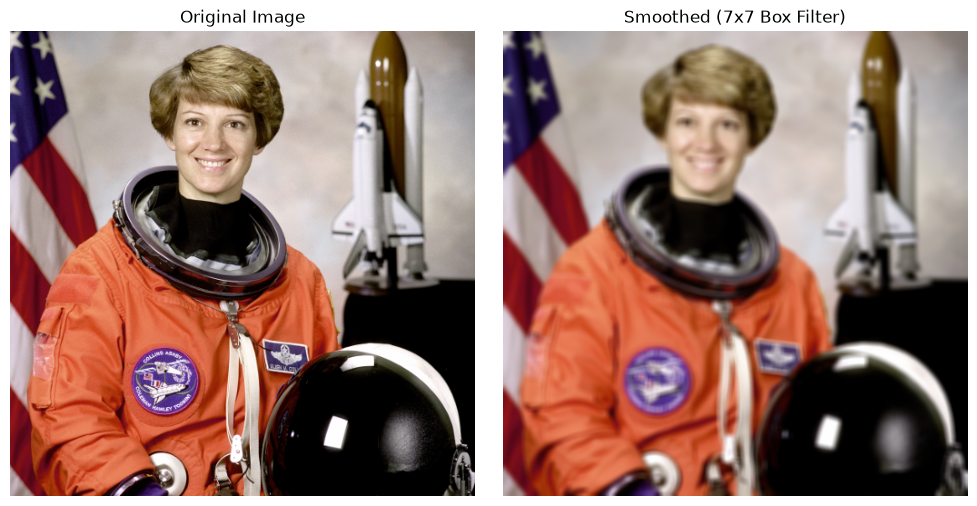

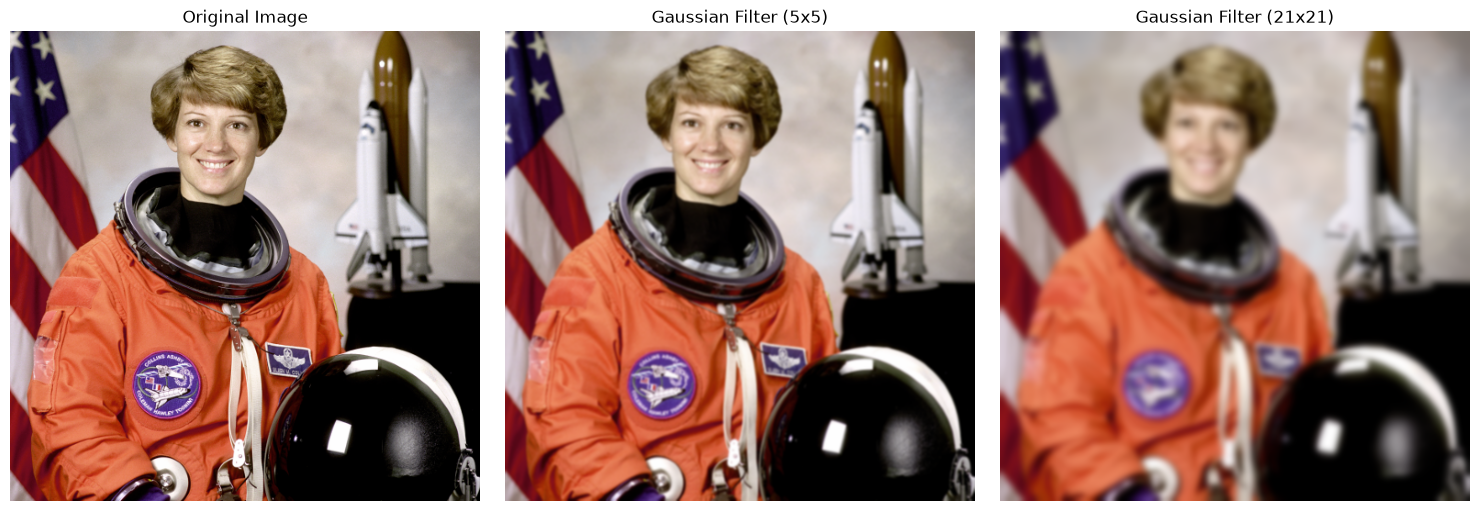

In [18]:
box_filtered = cv2.blur(image, (7, 7))

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(image)
ax[0].set_title("Original Image")
ax[0].axis("off")

ax[1].imshow(box_filtered)
ax[1].set_title("Smoothed (7x7 Box Filter)")
ax[1].axis("off")

plt.tight_layout()
plt.show()

gaussian_5x5 = cv2.GaussianBlur(image, (5, 5), 0)
gaussian_21x21 = cv2.GaussianBlur(image, (21, 21), 0)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(image)
ax[0].set_title("Original Image")
ax[0].axis("off")

ax[1].imshow(gaussian_5x5)
ax[1].set_title("Gaussian Filter (5x5)")
ax[1].axis("off")

ax[2].imshow(gaussian_21x21)
ax[2].set_title("Gaussian Filter (21x21)")
ax[2].axis("off")

plt.tight_layout()
plt.show()

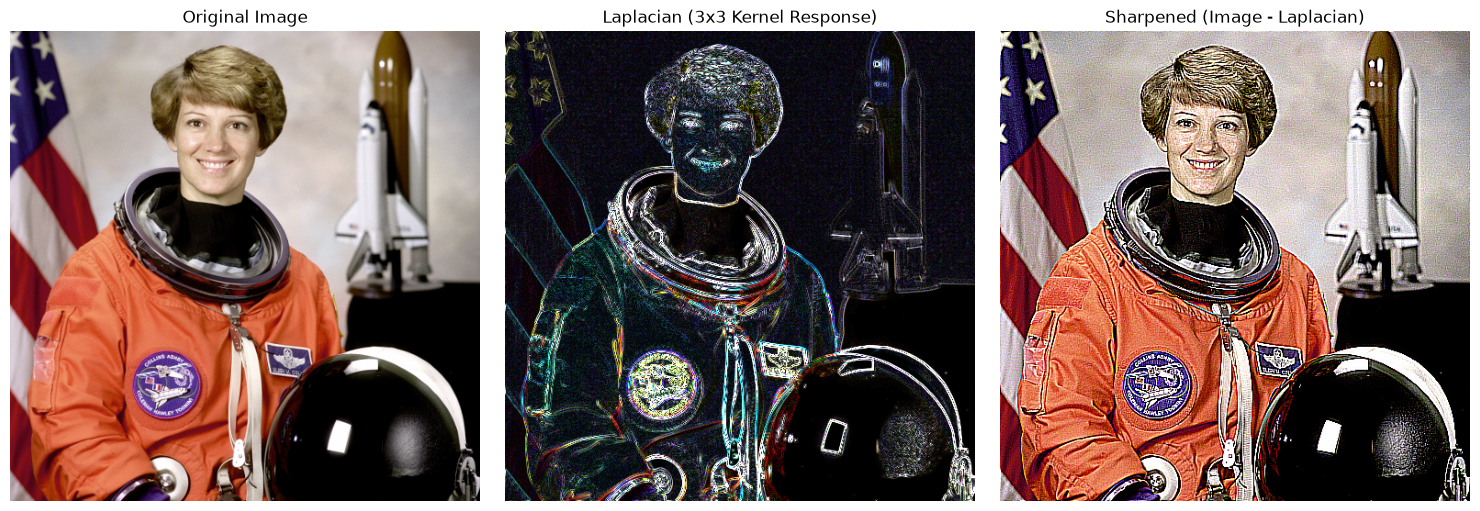

In [19]:
img_lap_float = image.astype(np.float32) / 255.0

laplacian = cv2.Laplacian(img_lap_float, cv2.CV_32F, ksize=3)

lap_sharpened = np.clip(img_lap_float - laplacian, 0, 1)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(img_lap_float)
ax[0].set_title("Original Image")
ax[0].axis("off")

ax[1].imshow(np.clip(np.abs(laplacian), 0, 1))
ax[1].set_title("Laplacian (3x3 Kernel Response)")
ax[1].axis("off")

ax[2].imshow(lap_sharpened)
ax[2].set_title("Sharpened (Image - Laplacian)")
ax[2].axis("off")

plt.tight_layout()
plt.show()